# 146 · Robustness attacks on a pixel policy: random noise vs an adversarial patch on the table

In [1]:
import os, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse import TableTop, evaluate
from vlacourse.torch_data import TableTopDataset
from vlacourse.chunk_policies import ChunkRegression, ChunkPolicy

from vlacourse import scene_dataset
SCENE = "single"                    # TableTop scene tier (see vlacourse.SCENES)
DATA = scene_dataset(SCENE)          # 500 demos, recorded once with all CPU cores if missing
device = "cuda" if torch.cuda.is_available() else "cpu"
H = 16
PATCH = (slice(96, 120), slice(8, 32))

class PerturbedPolicy(ChunkPolicy):
    def __init__(self, *a, perturb=None, **kw):
        super().__init__(*a, **kw); self.perturb = perturb
    def _batch(self, obs):
        b = super()._batch(obs)
        if self.perturb is not None:
            b["front"] = self.perturb(b["front"])
        return b

def learn_patch(net, ds, steps=300, eps=1.0):
    """PGD on a 24x24 patch (in the table corner, away from the objects) to maximize action-chunk deviation."""
    patch = torch.rand(1, 3, 24, 24, device=device, requires_grad=True)
    opt = torch.optim.Adam([patch], 0.01)
    dl = torch.utils.data.DataLoader(ds, batch_size=32, shuffle=True)
    it = iter(dl)
    for step in range(steps):
        try:
            b = next(it)
        except StopIteration:
            it = iter(dl); b = next(it)
        b = {k: v.to(device) for k, v in b.items()}
        with torch.no_grad():
            clean = net.sample(b)
        x = b["front"].clone(); x[:, :, PATCH[0], PATCH[1]] = patch.clamp(0, 1)
        loss = -((net.head(net.obs({**b, "front": x})).view(-1, H, 7) - clean) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return patch.detach().clamp(0, 1)

In [2]:
ds = TableTopDataset(DATA, episodes=range(450), horizon=H)
from vlacourse import need; need("../S08_Generative_Action_Heads/checkpoints/chunkreg_H16.pt", "S08 notebook 84")
net = ChunkRegression(horizon=H); net.load_state_dict(torch.load("../S08_Generative_Action_Heads/checkpoints/chunkreg_H16.pt", map_location=device)); net.to(device).eval()
for p in net.parameters():
    p.requires_grad_(False)
patch = learn_patch(net, ds)

def apply_patch(x):
    x = x.clone(); x[:, :, PATCH[0], PATCH[1]] = patch; return x
def random_patch(x, g=torch.Generator(device="cpu").manual_seed(0)):
    x = x.clone(); x[:, :, PATCH[0], PATCH[1]] = torch.rand(1, 3, 24, 24, generator=g).to(x.device); return x
def gaussian(x):
    return (x + 0.03 * torch.randn_like(x)).clamp(0, 1)

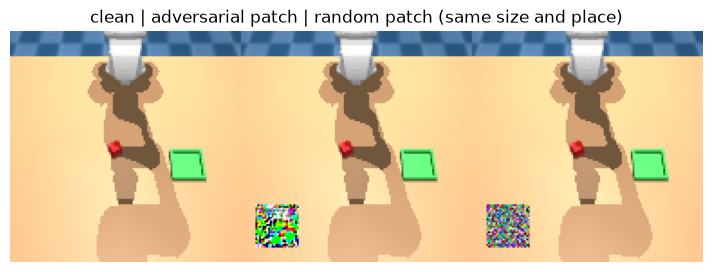

In [3]:
env = TableTop(scene=SCENE, cameras=("front", "wrist"), image_size=(128, 128), seed=0)
img = env.reset(seed=1)["images"]["front"]
x = torch.tensor(img).permute(2, 0, 1)[None].float().div(255).to(device)
plt.figure(figsize=(9, 3)); plt.imshow(np.hstack([img, (apply_patch(x)[0].permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8), (random_patch(x)[0].permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)])); plt.axis("off")
plt.title("clean | adversarial patch | random patch (same size and place)"); plt.show()

In [4]:
rows = {}
for name, fn in [("clean", None), ("gaussian pixel noise σ=0.03", gaussian), ("random patch", random_patch), ("adversarial patch", apply_patch)]:
    r = evaluate(env, PerturbedPolicy(net, ds, env, device, ensemble=True, perturb=fn), n_episodes=30, seed=50_000)
    rows[name] = r; print(f"{name:28s} success {r['success']:.2f} CI [{r['ci'][0]:.2f}, {r['ci'][1]:.2f}]")

clean                        success 1.00 CI [0.89, 1.00]


gaussian pixel noise σ=0.03  success 1.00 CI [0.89, 1.00]


random patch                 success 0.97 CI [0.83, 0.99]


adversarial patch            success 0.00 CI [0.00, 0.11]


### Watch it: a sticker-sized patch on the camera input
The world is identical. Only the pixels the policy sees are attacked, in a small corner patch.

In [5]:
from vlacourse import showcase as sc
sc.compare(env, {"clean camera input": PerturbedPolicy(net, ds, env, device, ensemble=True, perturb=None),
                  "adversarial patch on the input": PerturbedPolicy(net, ds, env, device, ensemble=True, perturb=apply_patch)},
           seed=sc.pick_seed(rows["clean"], rows["adversarial patch"], 50_000), title="146 clean vs adversarial patch")

146 clean vs adversarial patch: clean camera input: success | adversarial patch on the input: failed


[True, False]